Import Libraries

In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler

print("Libraries imported successfully")

Libraries imported successfully


Load CSV

In [23]:
# Load dataset from the current notebook folder
df = pd.read_csv(
    "C:\\Users\\Yazhini\\Desktop\\airbnb_pricing_analytics\\data\\clustering\\bank_transactions.csv",
    parse_dates=["TransactionDate"]
)

print("Dataset loaded successfully")
print("Dataset shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
df.head()

C:\Users\Yazhini\AppData\Local\Temp\ipykernel_11556\1886749139.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df = pd.read_csv(


Dataset loaded successfully
Dataset shape: (1048567, 9)

Columns:
['TransactionID', 'CustomerID', 'CustomerDOB', 'CustGender', 'CustLocation', 'CustAccountBalance', 'TransactionDate', 'TransactionTime', 'TransactionAmount (INR)']

First 5 rows:


,TransactionID,CustomerID,CustomerDOB,CustGender,CustLocation,CustAccountBalance,TransactionDate,TransactionTime,TransactionAmount (INR)
0,T1,C5841053,10/1/94,F,JAMSHEDPUR,17819.05,2016-02-08,143207,25.0
1,T2,C2142763,4/4/57,M,JHAJJAR,2270.69,2016-02-08,141858,27999.0
2,T3,C4417068,26/11/96,F,MUMBAI,17874.44,2016-02-08,142712,459.0
3,T4,C5342380,14/9/73,F,MUMBAI,866503.21,2016-02-08,142714,2060.0
4,T5,C9031234,24/3/88,F,NAVI MUMBAI,6714.43,2016-02-08,181156,1762.5


Identify columns

In [24]:
# Standardize column names
data = df.copy()
data.columns = data.columns.str.strip().str.replace(" ", "_")

# Detect customer ID column
customer_id_column = None
for column in data.columns:
    if "customerid" in column.lower():
        customer_id_column = column
        break

# Detect transaction date column
transaction_date_column = None
for column in data.columns:
    if "transactiondate" in column.lower():
        transaction_date_column = column
        break

# Detect transaction amount column
transaction_amount_column = None
for column in data.columns:
    if "transactionamount" in column.lower():
        transaction_amount_column = column
        break

# Detect account balance column
account_balance_column = None
for column in data.columns:
    if "accountbalance" in column.lower():
        account_balance_column = column
        break

# Detect date of birth column
dob_column = None
for column in ["DOB", "CustomerDOB", "DateOfBirth", "CustDOB"]:
    if column in data.columns:
        dob_column = column
        break

print("Customer ID column:", customer_id_column)
print("Transaction date column:", transaction_date_column)
print("Transaction amount column:", transaction_amount_column)
print("Account balance column:", account_balance_column)
print("Date of birth column:", dob_column)

Customer ID column: CustomerID
Transaction date column: TransactionDate
Transaction amount column: TransactionAmount_(INR)
Account balance column: CustAccountBalance
Date of birth column: CustomerDOB


Clean data

In [25]:
# Remove exact duplicate rows
data = data.drop_duplicates()

# Remove rows with missing essential values
essential_columns = [
    customer_id_column,
    transaction_date_column,
    transaction_amount_column,
    account_balance_column
]

data = data.dropna(subset=essential_columns)

# Remove invalid financial records
data = data[
    (data[transaction_amount_column] > 0) &
    (data[account_balance_column] >= 0)
]

# Convert CustomerID to string
data[customer_id_column] = data[customer_id_column].astype(str)

# Reset index
data = data.reset_index(drop=True)

print("Shape after cleaning:", data.shape)
print("\nMissing values after cleaning:")
print(data.isnull().sum())

Shape after cleaning: (1045368, 9)

Missing values after cleaning:
TransactionID                 0
CustomerID                    0
CustomerDOB                3386
CustGender                 1100
CustLocation                151
CustAccountBalance            0
TransactionDate               0
TransactionTime               0
TransactionAmount_(INR)       0
dtype: int64


Feature Engineering

In [26]:
if dob_column is not None:
    # Convert DOB to datetime
    data[dob_column] = pd.to_datetime(
        data[dob_column],
        errors="coerce"
    )

    # Reference date for calculating age
    reference_date = data[transaction_date_column].max()

    # Calculate age in years
    data["Age"] = (
        (reference_date - data[dob_column]).dt.days / 365.25
    )

    # Keep realistic ages only
    data = data[
        (data["Age"] >= 18) &
        (data["Age"] <= 100)
    ]

    print("Age feature created successfully.")
else:
    print("No DOB column found. Age feature will not be created.")

print("\nCurrent columns:")
print(data.columns.tolist())

C:\Users\Yazhini\AppData\Local\Temp\ipykernel_11556\3462914764.py:3: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  data[dob_column] = pd.to_datetime(


Age feature created successfully.

Current columns:
['TransactionID', 'CustomerID', 'CustomerDOB', 'CustGender', 'CustLocation', 'CustAccountBalance', 'TransactionDate', 'TransactionTime', 'TransactionAmount_(INR)', 'Age']


----EDA----

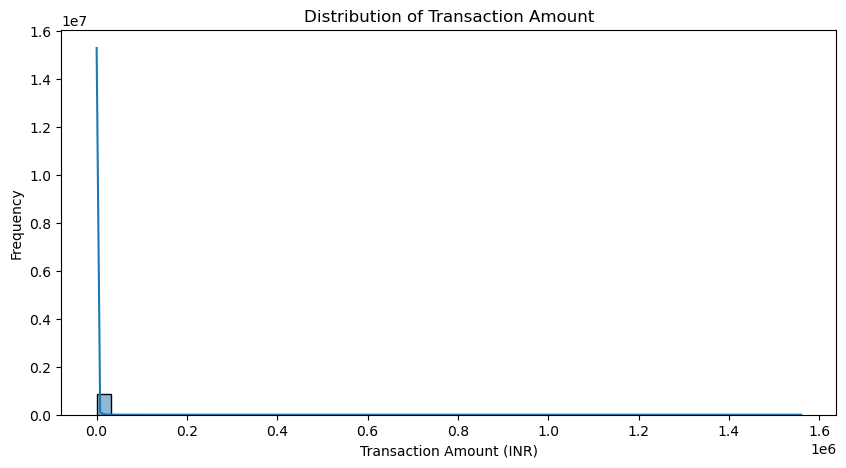

In [28]:
#Transaction Amount Distribution
plt.figure(figsize=(10, 5))
sns.histplot(data[transaction_amount_column], bins=50, kde=True)
plt.title("Distribution of Transaction Amount")
plt.xlabel("Transaction Amount (INR)")
plt.ylabel("Frequency")
plt.show()

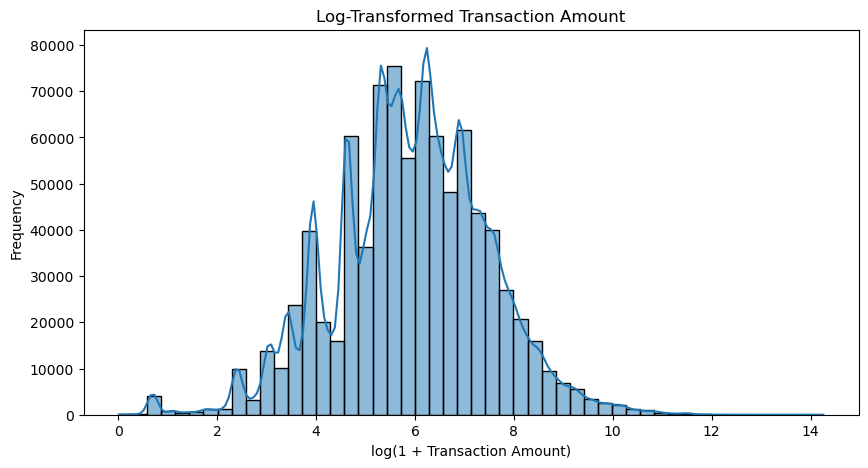

In [29]:
#Log-transformed Transaction Amount
plt.figure(figsize=(10, 5))
sns.histplot(
    np.log1p(data[transaction_amount_column]),
    bins=50,
    kde=True
)
plt.title("Log-Transformed Transaction Amount")
plt.xlabel("log(1 + Transaction Amount)")
plt.ylabel("Frequency")
plt.show()

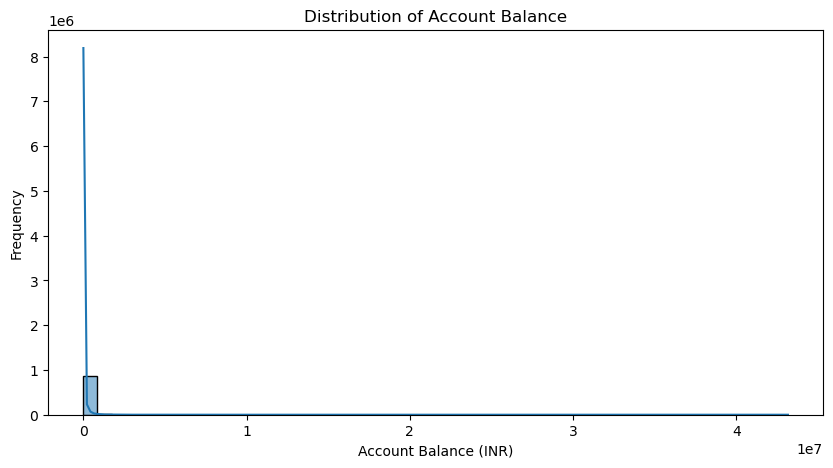

In [30]:
#Account balance distribution
plt.figure(figsize=(10, 5))
sns.histplot(data[account_balance_column], bins=50, kde=True)
plt.title("Distribution of Account Balance")
plt.xlabel("Account Balance (INR)")
plt.ylabel("Frequency")
plt.show()

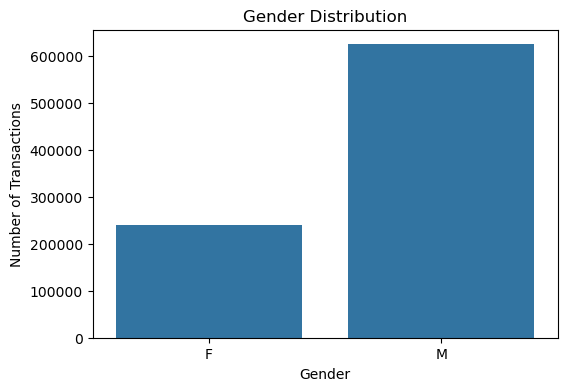

In [31]:
#Gender distribution
gender_column = None

for column in data.columns:
    if "gender" in column.lower():
        gender_column = column
        break

if gender_column is not None:
    plt.figure(figsize=(6, 4))
    sns.countplot(x=gender_column, data=data)
    plt.title("Gender Distribution")
    plt.xlabel("Gender")
    plt.ylabel("Number of Transactions")
    plt.show()
else:
    print("No gender column found.")

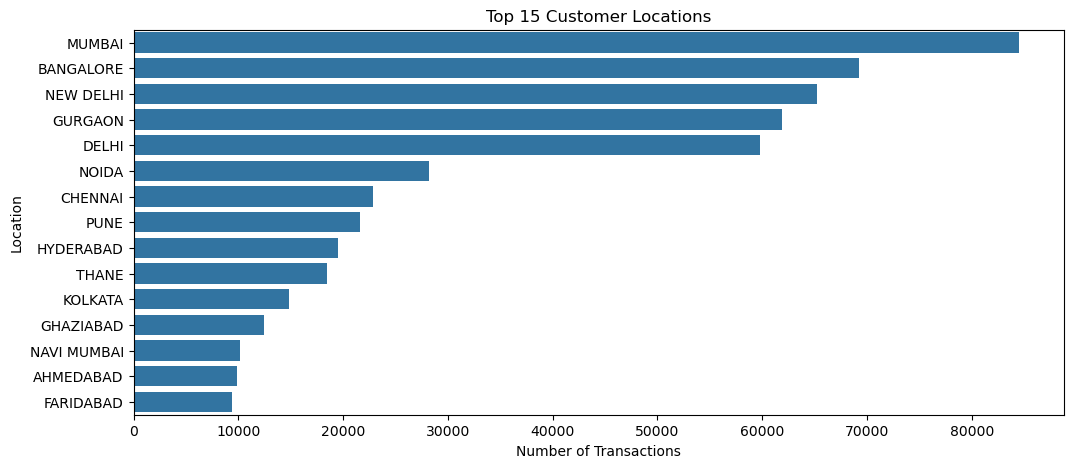

In [32]:
#Top Location
location_column = None

for column in data.columns:
    if "location" in column.lower():
        location_column = column
        break

if location_column is not None:
    top_locations = data[location_column].value_counts().head(15)

    plt.figure(figsize=(12, 5))
    sns.barplot(x=top_locations.values, y=top_locations.index)
    plt.title("Top 15 Customer Locations")
    plt.xlabel("Number of Transactions")
    plt.ylabel("Location")
    plt.show()
else:
    print("No location column found.")

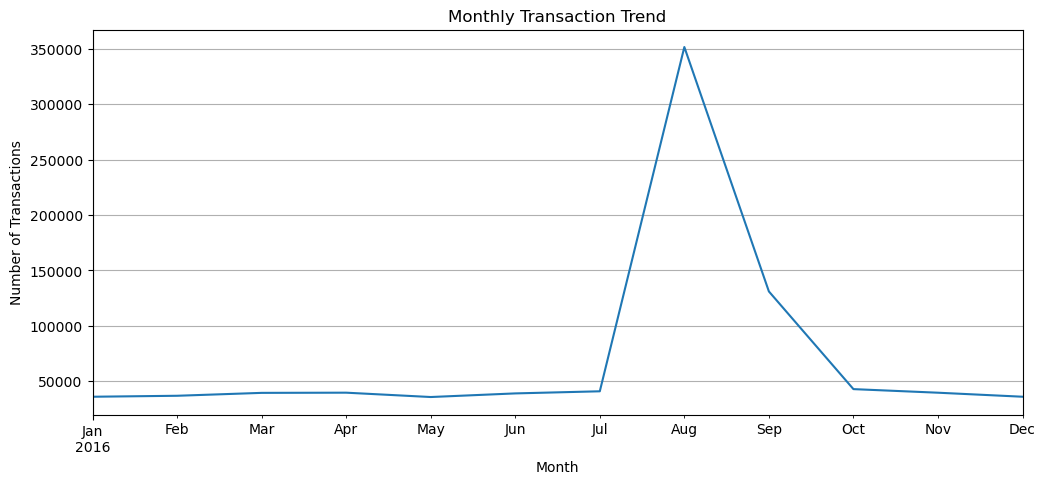

In [33]:
#Monthly-Transaction Trend
data["TransactionMonth"] = data[transaction_date_column].dt.to_period("M")

monthly_transactions = data.groupby("TransactionMonth").size()

plt.figure(figsize=(12, 5))
monthly_transactions.plot()
plt.title("Monthly Transaction Trend")
plt.xlabel("Month")
plt.ylabel("Number of Transactions")
plt.grid(True)
plt.show()

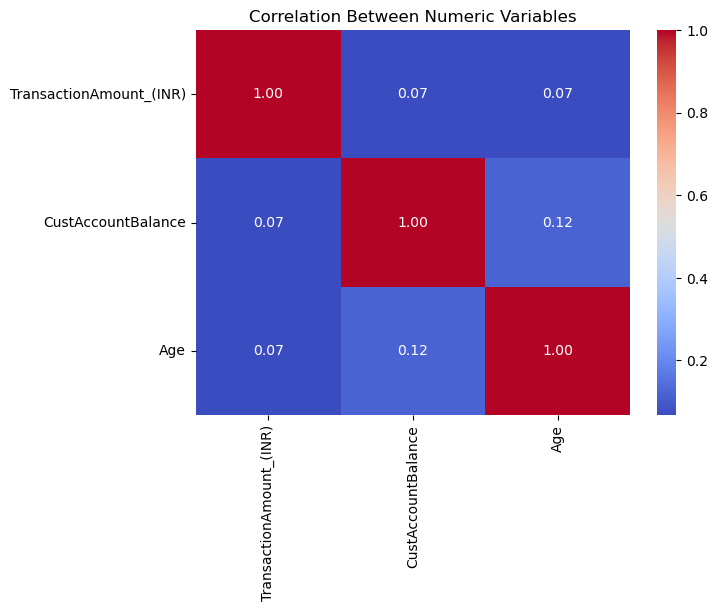

In [34]:
#Correlation-Heatmap
numeric_columns = [
    transaction_amount_column,
    account_balance_column
]

if "Age" in data.columns:
    numeric_columns.append("Age")

plt.figure(figsize=(7, 5))
sns.heatmap(
    data[numeric_columns].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Between Numeric Variables")
plt.show()

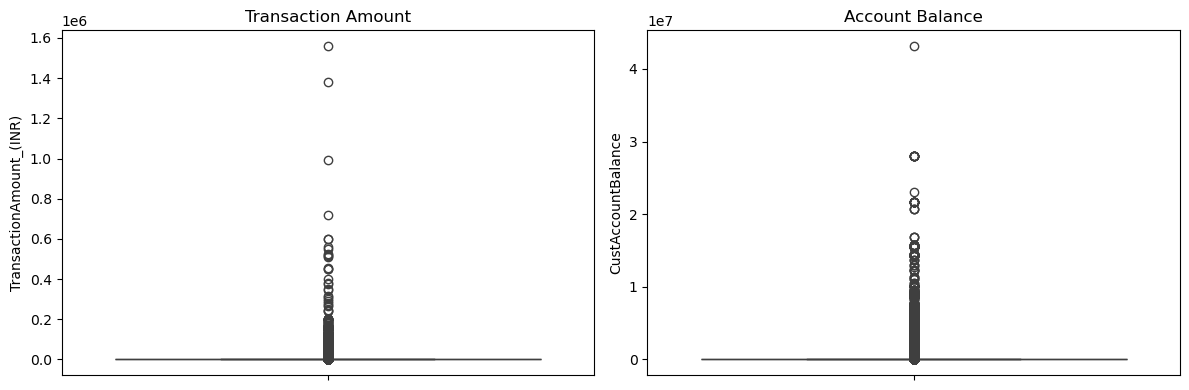

In [35]:
#Outlier-Visualisation
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
sns.boxplot(y=data[transaction_amount_column])
plt.title("Transaction Amount")

plt.subplot(1, 2, 2)
sns.boxplot(y=data[account_balance_column])
plt.title("Account Balance")

plt.tight_layout()
plt.show()

-----Feature Engineering-----

In [36]:
# Reference date for recency calculation
snapshot_date = data[transaction_date_column].max() + pd.Timedelta(days=1)

# Create customer-level features
customer_features = data.groupby(customer_id_column).agg(
    Recency=(
        transaction_date_column,
        lambda x: (snapshot_date - x.max()).days
    ),
    Frequency=(transaction_date_column, "count"),
    Monetary=(transaction_amount_column, "sum"),
    AvgTransactionAmount=(transaction_amount_column, "mean"),
    MaxTransactionAmount=(transaction_amount_column, "max"),
    AvgAccountBalance=(account_balance_column, "mean"),
    MaxAccountBalance=(account_balance_column, "max")
).reset_index()

# Rename CustomerID column
customer_features = customer_features.rename(
    columns={customer_id_column: "CustomerID"}
)

# Derived feature: average spend per transaction
customer_features["AmountPerTransaction"] = (
    customer_features["Monetary"] /
    customer_features["Frequency"]
)

# Derived feature: balance relative to spending
customer_features["BalanceToSpendRatio"] = (
    customer_features["AvgAccountBalance"] /
    (customer_features["Monetary"] + 1)
)

# Add Age only if it exists
if "Age" in data.columns:
    age_features = data.groupby(customer_id_column)["Age"].mean().reset_index()
    age_features = age_features.rename(
        columns={customer_id_column: "CustomerID"}
    )

    customer_features = customer_features.merge(
        age_features,
        on="CustomerID",
        how="left"
    )

print("Customer-level dataset shape:", customer_features.shape)
customer_features.head()

Customer-level dataset shape: (751222, 11)


,CustomerID,Recency,Frequency,Monetary,AvgTransactionAmount,MaxTransactionAmount,AvgAccountBalance,MaxAccountBalance,AmountPerTransaction,BalanceToSpendRatio,Age
0,C1010011,75,2,5106.0,2553.0,4750.0,76340.635,120180.54,2553.0,14.948235,28.948665
1,C1010012,118,1,1499.0,1499.0,1499.0,24204.490,24204.49,1499.0,16.136327,22.368241
2,C1010014,155,2,1455.0,727.5,1205.0,100112.950,161848.76,727.5,68.758894,28.491444
3,C1010018,86,1,30.0,30.0,30.0,496.180,496.18,30.0,16.005806,26.532512
4,C1010028,103,1,557.0,557.0,557.0,296828.370,296828.37,557.0,531.950484,28.290212


---Select Clustering Features---

In [37]:
# Base clustering features
clustering_features = [
    "Recency",
    "Frequency",
    "Monetary",
    "AvgTransactionAmount",
    "MaxTransactionAmount",
    "AvgAccountBalance",
    "MaxAccountBalance",
    "AmountPerTransaction",
    "BalanceToSpendRatio"
]

# Add Age only if available
if "Age" in customer_features.columns:
    clustering_features.append("Age")

X = customer_features[clustering_features].copy()

print("Selected clustering features:")
print(clustering_features)

print("\nShape before preprocessing:")
print(X.shape)

Selected clustering features:
['Recency', 'Frequency', 'Monetary', 'AvgTransactionAmount', 'MaxTransactionAmount', 'AvgAccountBalance', 'MaxAccountBalance', 'AmountPerTransaction', 'BalanceToSpendRatio', 'Age']

Shape before preprocessing:
(751222, 10)


---Reduce Skewness---

In [38]:
# Apply log transformation to skewed features
log_features = [
    "Monetary",
    "AvgTransactionAmount",
    "MaxTransactionAmount",
    "AvgAccountBalance",
    "MaxAccountBalance",
    "AmountPerTransaction",
    "BalanceToSpendRatio"
]

for column in log_features:
    X[column] = np.log1p(X[column])

print("Log transformation completed.")
X.describe().T

Log transformation completed.


,count,mean,std,min,25%,50%,75%,max
Recency,751222.0,131.395879,80.798589,1.000000,87.000000,111.000000,155.000000,337.000000
Frequency,751222.0,1.152912,0.405596,1.000000,1.000000,1.000000,1.000000,6.000000
Monetary,751222.0,6.077335,1.560301,0.009950,5.164786,6.175867,7.109675,14.260219
AvgTransactionAmount,751222.0,5.976370,1.512256,0.009950,5.065439,6.028279,6.937314,14.260219
MaxTransactionAmount,751222.0,6.039870,1.545497,0.009950,5.135798,6.115892,7.047517,14.260219
AvgAccountBalance,751222.0,9.361647,2.352509,0.000000,8.477267,9.657444,10.777265,17.146986
MaxAccountBalance,751222.0,9.431984,2.385578,0.000000,8.520077,9.728278,10.881070,17.580553
AmountPerTransaction,751222.0,5.976370,1.512256,0.009950,5.065439,6.028279,6.937314,14.260219
BalanceToSpendRatio,751222.0,3.551703,1.976057,0.000000,2.171670,3.547629,4.853636,14.848975
Age,751222.0,29.007123,4.778855,18.004107,25.393566,28.383299,32.169747,40.939083


---Handle Outliers---

In [39]:
# IQR-based outlier capping
def cap_outliers_iqr(column):
    Q1 = X[column].quantile(0.25)
    Q3 = X[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    X[column] = X[column].clip(lower_limit, upper_limit)

for column in clustering_features:
    cap_outliers_iqr(column)

print("Outlier capping completed.")
X.describe().T

Outlier capping completed.


,count,mean,std,min,25%,50%,75%,max
Recency,751222.0,125.968759,69.332471,1.000000,87.000000,111.000000,155.000000,257.000000
Frequency,751222.0,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000
Monetary,751222.0,6.082687,1.523943,2.247452,5.164786,6.175867,7.109675,10.027009
AvgTransactionAmount,751222.0,5.980683,1.472155,2.257627,5.065439,6.028279,6.937314,9.745127
MaxTransactionAmount,751222.0,6.044688,1.506638,2.268220,5.135798,6.115892,7.047517,9.915095
AvgAccountBalance,751222.0,9.477470,2.030006,5.027270,8.477267,9.657444,10.777265,14.227261
MaxAccountBalance,751222.0,9.544653,2.072772,4.978587,8.520077,9.728278,10.881070,14.422561
AmountPerTransaction,751222.0,5.980683,1.472155,2.257627,5.065439,6.028279,6.937314,9.745127
BalanceToSpendRatio,751222.0,3.545280,1.955699,0.000000,2.171670,3.547629,4.853636,8.876585
Age,751222.0,29.007123,4.778855,18.004107,25.393566,28.383299,32.169747,40.939083


---Feature Scaling---

In [40]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=clustering_features
)

print("Final scaled dataset shape:", X_scaled_df.shape)
X_scaled_df.head()

Final scaled dataset shape: (751222, 10)


,Recency,Frequency,Monetary,AvgTransactionAmount,MaxTransactionAmount,AvgAccountBalance,MaxAccountBalance,AmountPerTransaction,BalanceToSpendRatio,Age
0,-0.735136,0.0,1.611400,1.266670,1.607170,0.869705,1.038275,1.266670,-0.396754,-0.012233
1,-0.114936,0.0,0.807467,0.905162,0.841963,0.303874,0.265192,0.905162,-0.360014,-1.389221
2,0.418725,0.0,0.787931,0.414566,0.697166,1.003246,1.181882,0.414566,0.357808,-0.107909
3,-0.576480,0.0,-1.738059,-1.729911,-1.732799,-1.610104,-1.609296,-1.729911,-0.363924,-0.517826
4,-0.331285,0.0,0.158583,0.233451,0.185626,1.538639,1.474481,0.233451,1.397531,-0.150017


---Validate Final Dataset---

In [41]:
print("Final dataset shape:", X_scaled_df.shape)
print("Missing values:", X_scaled_df.isnull().sum().sum())
print("Infinite values:", np.isinf(X_scaled_df).sum().sum())
print("Duplicate customers:", customer_features["CustomerID"].duplicated().sum())

print("\nScaled feature summary:")
print(X_scaled_df.describe().round(3).T)

# Save customer-level engineered dataset
customer_features.to_csv(
    "bank_customer_features.csv",
    index=False
)

Final dataset shape: (751222, 10)
Missing values: 0
Infinite values: 0
Duplicate customers: 0

Scaled feature summary:
                         count  mean  std    min    25%    50%    75%    max
Recency               751222.0  -0.0  1.0 -1.802 -0.562 -0.216  0.419  1.890
Frequency             751222.0   0.0  0.0  0.000  0.000  0.000  0.000  0.000
Monetary              751222.0  -0.0  1.0 -2.517 -0.602  0.061  0.674  2.588
AvgTransactionAmount  751222.0   0.0  1.0 -2.529 -0.622  0.032  0.650  2.557
MaxTransactionAmount  751222.0  -0.0  1.0 -2.507 -0.603  0.047  0.666  2.569
AvgAccountBalance     751222.0  -0.0  1.0 -2.192 -0.493  0.089  0.640  2.340
MaxAccountBalance     751222.0   0.0  1.0 -2.203 -0.494  0.089  0.645  2.353
AmountPerTransaction  751222.0   0.0  1.0 -2.529 -0.622  0.032  0.650  2.557
BalanceToSpendRatio   751222.0   0.0  1.0 -1.813 -0.702  0.001  0.669  2.726
Age                   751222.0   0.0  1.0 -2.302 -0.756 -0.131  0.662  2.497
Files saved successfully:
- bank_c